# Customer Churn - Exploratory Data Analysis
IBM Telco Customer Churn dataset. Every number and chart below is computed from the downloaded CSV when the notebook runs.
The notebook can also be opened in Google Colab: clone the repository, `pip install -r requirements.txt`, then run it from the `notebooks/` folder.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # make `src` importable when run from notebooks/

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from src import eda
from src.config import FIGURES_DIR, TARGET
from src.data_loader import inspect_data, load_data
from src.preprocessing import clean_data

pd.set_option("display.max_columns", 30)

## 5.1 Initial inspection

In [2]:
raw = load_data()          # downloads the CSV on first use, then reuses the local copy
report = inspect_data(raw, verbose=False)
print(f"Dimensions: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
display(raw.head()); display(raw.tail())

Dimensions: 7,043 rows x 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [3]:
display(pd.DataFrame({"dtype": raw.dtypes.astype(str), "non_null": raw.notna().sum(), "unique": raw.nunique()}))

,dtype,non_null,unique
customerID,str,7043,7043
gender,str,7043,2
SeniorCitizen,int64,7043,2
Partner,str,7043,2
Dependents,str,7043,2
tenure,int64,7043,73
PhoneService,str,7043,2
MultipleLines,str,7043,3
InternetService,str,7043,3
OnlineSecurity,str,7043,3


In [4]:
display(raw.describe().round(2))

,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


In [5]:
# Frequency distribution of every categorical column
cats = [c for c in raw.columns if c not in ("customerID", "tenure", "MonthlyCharges", "TotalCharges")]
for c in cats:
    print(f"\n{c}"); print(raw[c].value_counts().to_string())


gender
gender
Male      3555
Female    3488

SeniorCitizen
SeniorCitizen
0    5901
1    1142

Partner
Partner
No     3641
Yes    3402

Dependents
Dependents
No     4933
Yes    2110

PhoneService
PhoneService
Yes    6361
No      682

MultipleLines
MultipleLines
No                  3390
Yes                 2971
No phone service     682

InternetService
InternetService
Fiber optic    3096
DSL            2421
No             1526

OnlineSecurity
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526

OnlineBackup
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526

DeviceProtection
DeviceProtection
No                     3095
Yes                    2422
No internet service    1526

TechSupport
TechSupport
No                     3473
Yes                    2044
No internet service    1526

StreamingTV
StreamingTV
No                     2810
Yes                    2707
No internet service    1526

Stream

## 5.2 Data quality
`TotalCharges` is stored as text in the raw file, which usually means some entries cannot be converted to numbers. The checks below find them rather than assume.

In [6]:
print("Missing (NaN) values:", report["missing_values"] or "none")
print("Blank strings:", report["blank_strings"] or "none")
print("Duplicate rows:", report["duplicate_rows"], "| duplicate customer IDs:", report["duplicate_ids"])
print("Problems detected:", report["problems"] or "none")
blank = raw[raw["TotalCharges"].astype(str).str.strip() == ""]
print(f"\nRows with blank TotalCharges: {len(blank)}")
print("Their tenure values:", sorted(blank["tenure"].unique()), "| their Churn values:", sorted(blank["Churn"].unique()))

Missing (NaN) values: none
Blank strings: {'TotalCharges': 11}
Duplicate rows: 0 | duplicate customer IDs: 0
Problems detected: ['TotalCharges: 11 non-numeric/blank entries']

Rows with blank TotalCharges: 11
Their tenure values: [np.int64(0)] | their Churn values: ['No']


**Cleaning decision.** If the blank `TotalCharges` rows all have `tenure == 0`, the customers have not been billed yet, so 0 is a logical value; `clean_data` applies exactly this rule. Any other missing numeric value would be median-imputed inside the model pipeline using training data only. No records are removed.

In [7]:
df = clean_data(raw)
print("Missing values after cleaning:", int(df[["tenure", "MonthlyCharges", "TotalCharges"]].isna().sum().sum()))
print("Target values:", sorted(df[TARGET].unique()))
display(eda.iqr_outliers(df))

Missing values after cleaning: 0
Target values: ['No', 'Yes']


,q1,q3,iqr,lower,upper,flagged
feature,,,,,,
tenure,9.00,55.00,46.00,-60.00,124.00,0
MonthlyCharges,35.50,89.85,54.35,-46.02,171.38,0
TotalCharges,398.55,3786.60,3388.05,-4683.52,8868.67,0


A value flagged by the IQR rule is only a candidate for inspection - it is not removed automatically.

## 5.3 Customer churn analysis

In [8]:
summary = eda.churn_summary(df)
display(summary)
print(f"{summary.loc['Yes','customers']:,} customers churned ({summary.loc['Yes','percentage']}%) and "
      f"{summary.loc['No','customers']:,} stayed ({summary.loc['No','percentage']}%).")

,customers,percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


1,869 customers churned (26.54%) and 5,174 stayed (73.46%).


In [9]:
for col in ["Contract", "PaymentMethod", "InternetService", "SeniorCitizen", "Dependents", "TechSupport"]:
    print(f"\nChurn rate by {col}")
    display(eda.churn_rate_by(df, col))


Churn rate by Contract


,customers,churned,churn_rate_pct
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83



Churn rate by PaymentMethod


,customers,churned,churn_rate_pct
PaymentMethod,,,
Electronic check,2365,1071,45.29
Mailed check,1612,308,19.11
Bank transfer (automatic),1544,258,16.71
Credit card (automatic),1522,232,15.24



Churn rate by InternetService


...

,customers,churned,churn_rate_pct
SeniorCitizen,,,
Yes,1142,476,41.68
No,5901,1393,23.61



Churn rate by Dependents


,customers,churned,churn_rate_pct
Dependents,,,
No,4933,1543,31.28
Yes,2110,326,15.45



Churn rate by TechSupport


,customers,churned,churn_rate_pct
TechSupport,,,
No,3473,1446,41.64
Yes,2044,310,15.17
No internet service,1526,113,7.40


In [10]:
display(df.groupby(TARGET)[["tenure", "MonthlyCharges", "TotalCharges"]].agg(["mean", "median"]).round(2))

tenure        MonthlyCharges        TotalCharges         
        mean median           mean median         mean   median
Churn                                                          
No     37.57   38.0          61.27  64.43      2549.91  1679.52
Yes    17.98   10.0          74.44  79.65      1531.80   703.55

## 5.4 Statistical analysis

In [11]:
display(df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(2))
print("\nCross-tabulation: Contract x Churn (row %)")
display((pd.crosstab(df["Contract"], df[TARGET], normalize="index") * 100).round(2))
print("\nCorrelation with churn (1 = churned):")
display(eda.correlation_matrix(df)["Churn"].drop("Churn").round(3).to_frame("correlation"))

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80



Cross-tabulation: Contract x Churn (row %)


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83



Correlation with churn (1 = churned):


,correlation
tenure,-0.352
MonthlyCharges,0.193
TotalCharges,-0.198
SeniorCitizen,0.151


Correlation measures linear association only; it does not show that a feature causes churn.

## 5.5 Required visualizations

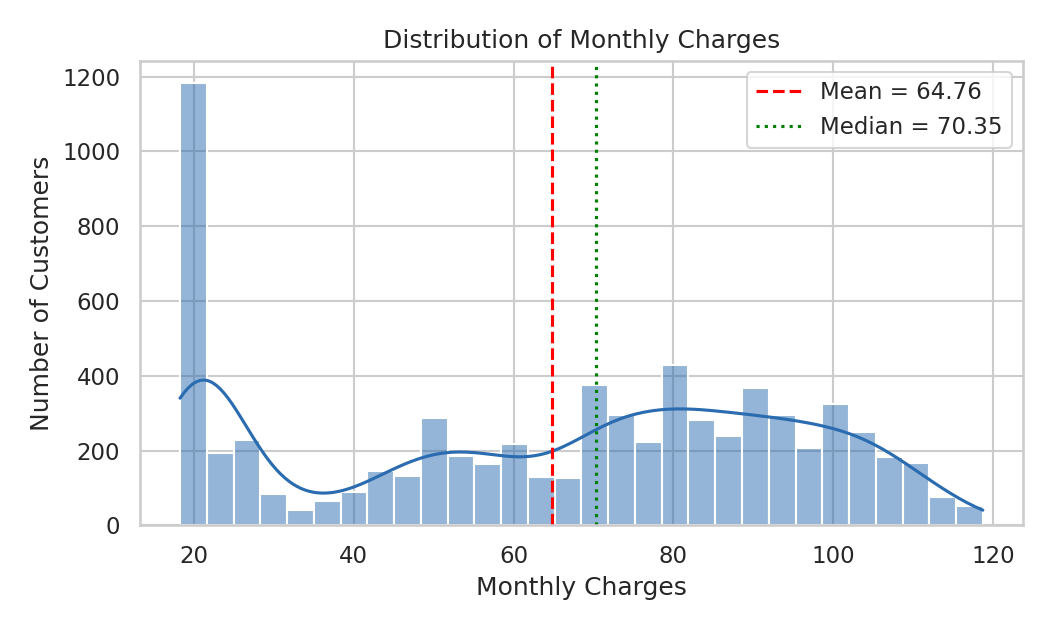

Mean 64.76, median 70.35, std 30.09. A mean below the median together with several peaks indicates a skewed, multi-modal distribution.


In [12]:
def show(fig, name):
    path = FIGURES_DIR / name
    fig.savefig(path, dpi=150); plt.close(fig)
    display(Image(filename=str(path)))

show(eda.plot_monthly_charges(df), "eda_01_monthly_charges.png")
print(f"Mean {df['MonthlyCharges'].mean():.2f}, median {df['MonthlyCharges'].median():.2f}, std {df['MonthlyCharges'].std():.2f}. "
      "A mean below the median together with several peaks indicates a skewed, multi-modal distribution.")

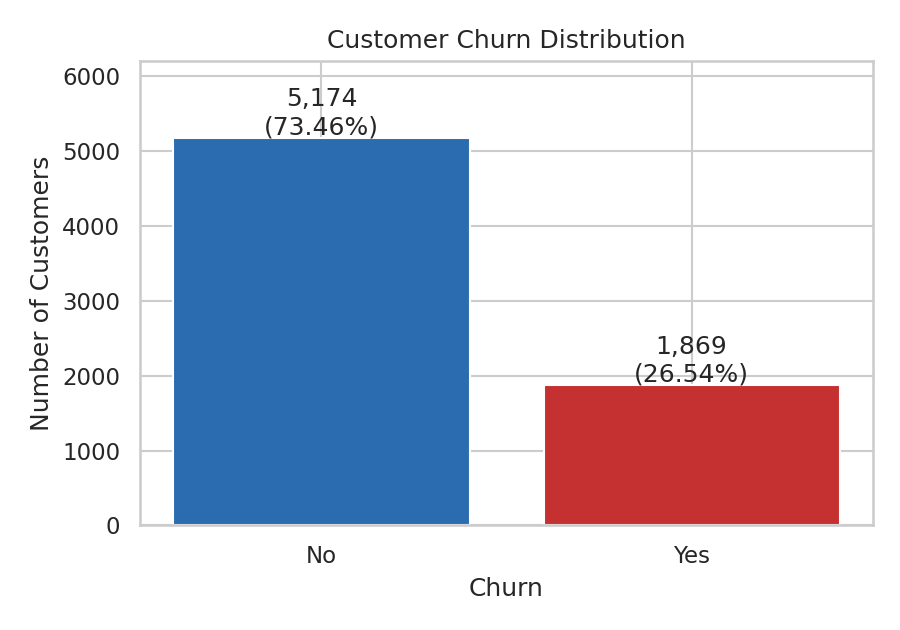

The majority class is 2.8x larger than the minority class, so accuracy alone would be misleading.


In [13]:
show(eda.plot_churn_distribution(df), "eda_02_churn_distribution.png")
print(f"The majority class is {summary.loc['No','customers']/summary.loc['Yes','customers']:.1f}x larger than the minority class, "
      "so accuracy alone would be misleading.")

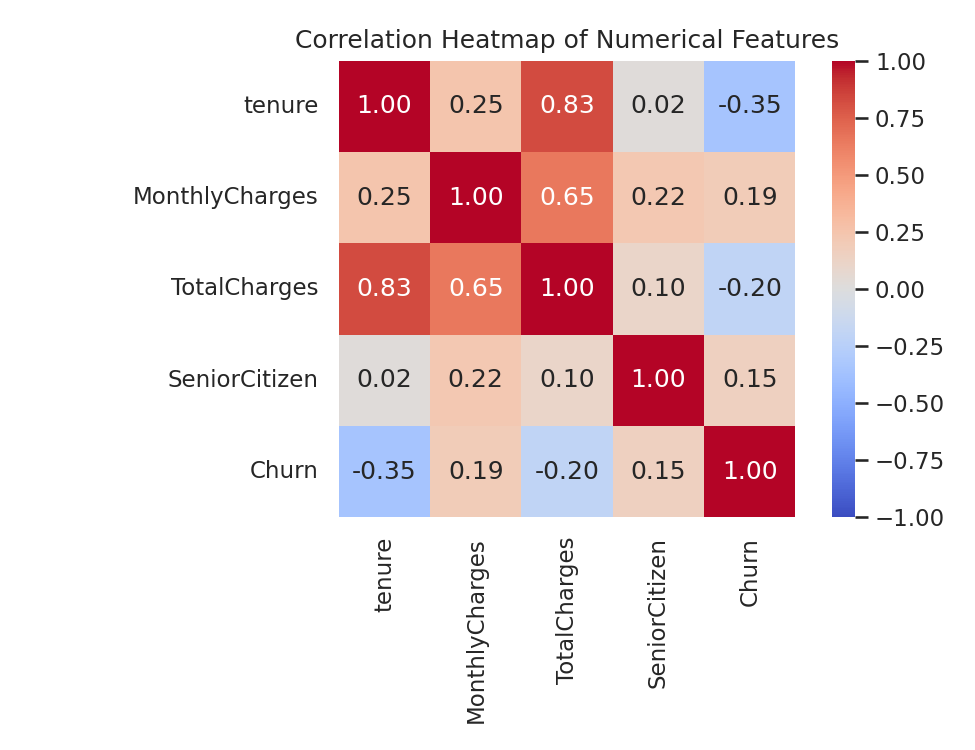

tenure vs TotalCharges: r = 0.83 (overlapping information); tenure vs Churn: r = -0.35; MonthlyCharges vs Churn: r = 0.19.


In [14]:
show(eda.plot_correlation(df), "eda_03_correlation_heatmap.png")
c = eda.correlation_matrix(df)
print(f"tenure vs TotalCharges: r = {c.loc['tenure','TotalCharges']:.2f} (overlapping information); "
      f"tenure vs Churn: r = {c.loc['tenure','Churn']:.2f}; MonthlyCharges vs Churn: r = {c.loc['MonthlyCharges','Churn']:.2f}.")

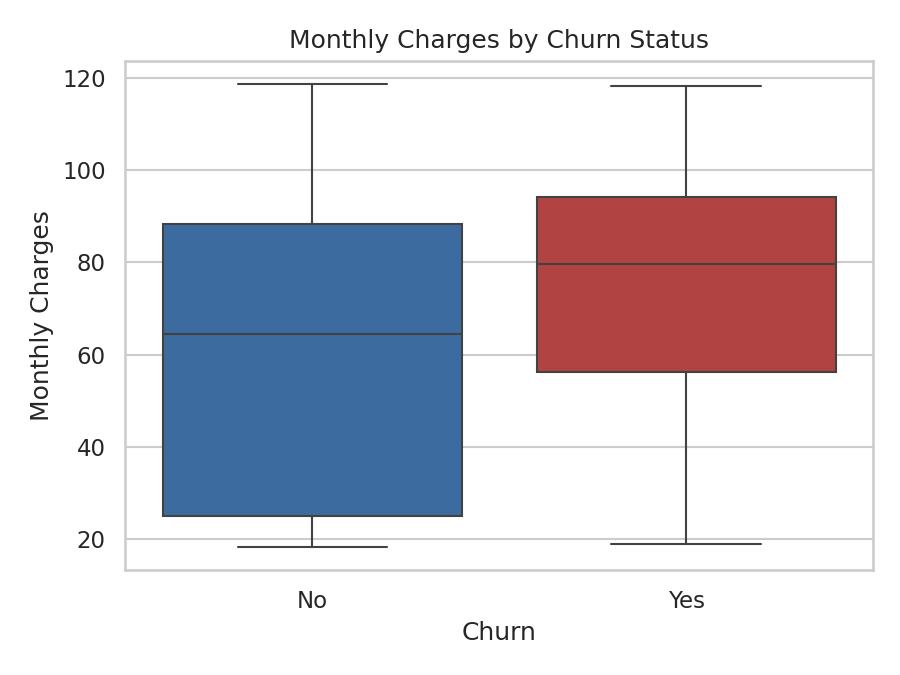

Median monthly charge - stayed: 64.43, churned: 79.65.


In [15]:
show(eda.plot_monthly_by_churn(df), "eda_04_monthly_charges_by_churn.png")
med = df.groupby(TARGET)["MonthlyCharges"].median()
print(f"Median monthly charge - stayed: {med['No']:.2f}, churned: {med['Yes']:.2f}.")

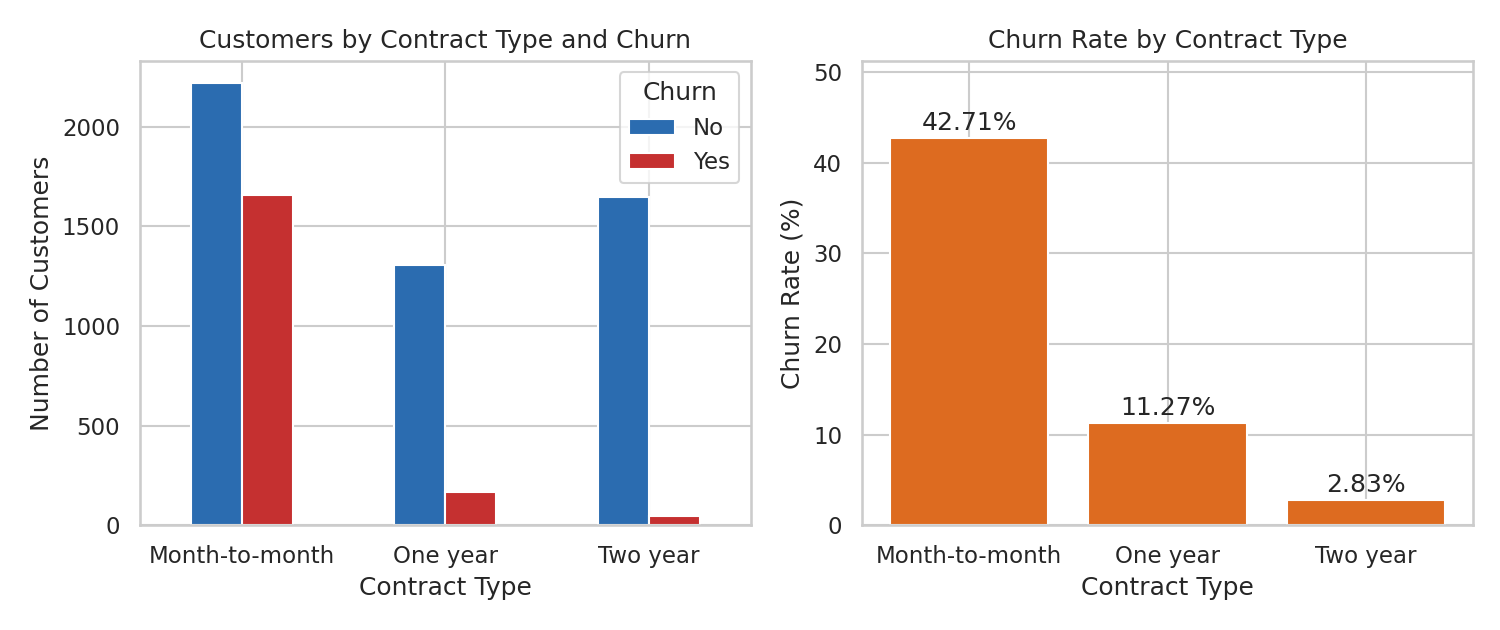

,customers,churned,churn_rate_pct
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


Churn rate is highest for 'Month-to-month' (42.71%) and lowest for 'Two year' (2.83%). This is an association, not proof that contract type causes churn.


In [16]:
show(eda.plot_churn_by_contract(df), "eda_05_churn_by_contract.png")
ct = eda.churn_rate_by(df, "Contract")
display(ct)
print(f"Churn rate is highest for '{ct.index[0]}' ({ct.iloc[0]['churn_rate_pct']}%) and lowest for '{ct.index[-1]}' "
      f"({ct.iloc[-1]['churn_rate_pct']}%). This is an association, not proof that contract type causes churn.")

### Additional charts

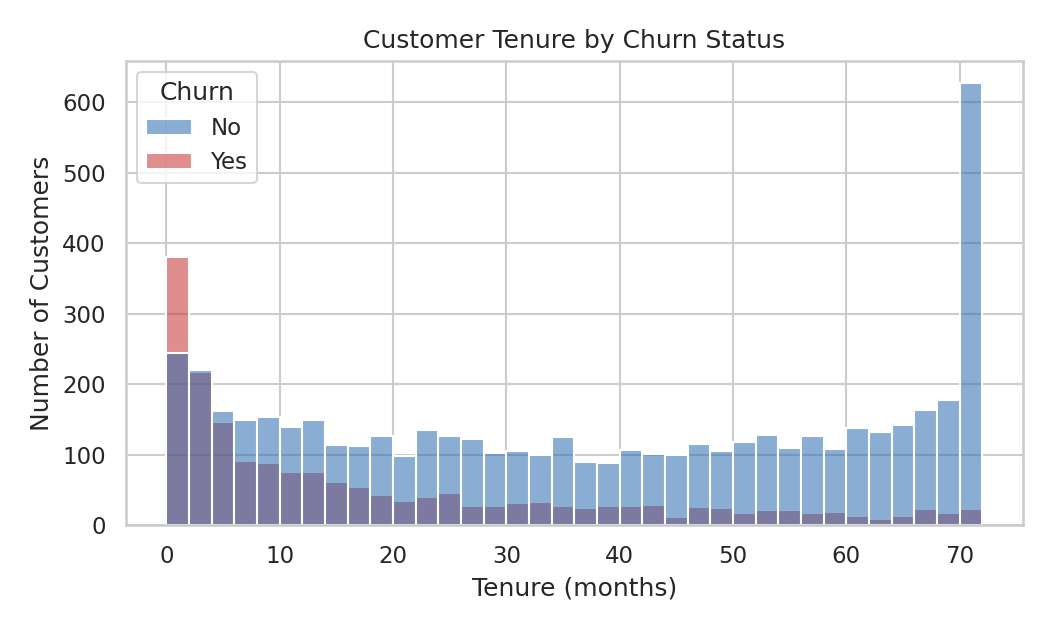

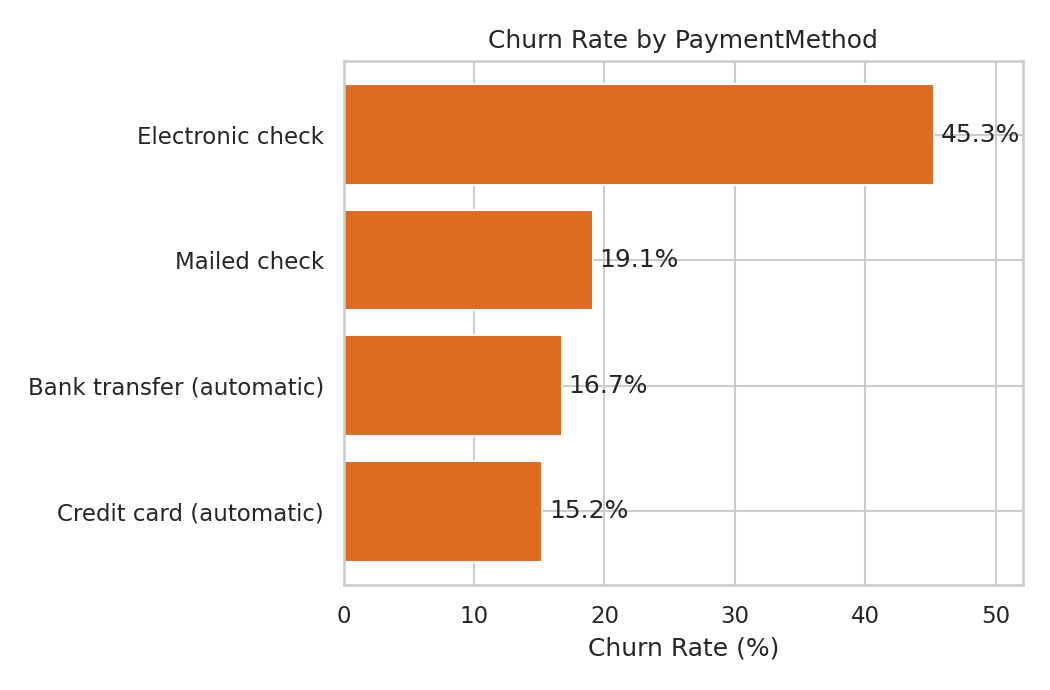

In [17]:
show(eda.plot_tenure_by_churn(df), "eda_06_tenure_by_churn.png")
show(eda.plot_churn_rate_by_category(df, "PaymentMethod"), "eda_07_churn_by_payment_method.png")

## 5.6 Findings and limitations
The written summary is generated from the same functions: `python -m src.eda` writes `reports/eda_summary.md`.

In [18]:
path = eda.write_summary(df, raw=raw)
print("Wrote", path)

Wrote /home/claude/repo/customer-churn-prediction-deep-learning/reports/eda_summary.md


**Limitations.** The data are an IBM sample dataset with a single time snapshot; representativeness is unknown. All findings are associations. Descriptive statistics here use the full dataset, whereas every model-fitting step (imputation, scaling, encoding, training) uses the training split only.